In [1]:
## Analysis of weights got with weighted logistic regression

import numpy as np
import matplotlib.pyplot as plt

#We put the weights in a dictionary for easier handling
weights = {
    "_CASTHM1": -0.0135, "FLUSHOT6": 0.0073, "METVL11_": -0.0045, "_PASTRNG": -0.0037,
    "EDUCA": -0.0247, "CHCCOPD1": -0.1326, "DRADVISE": -0.0637, "CHCKIDNY": -0.0843,
    "ARTHSOCL": 0.0062, "MENTHLTH": 0.0041, "SMOKE100": -0.0817, "DOCTDIAB": -0.0005,
    "DIABAGE2": -0.0055, "VETERAN3": -0.0595, "CHKHEMO3": 0.0073, "SEX": -0.2451,
    "_DRNKWEK": -0.0008, "JOINPAIN": 0.0224, "MARITAL": -0.0073, "EXERANY2": 0.0054,
    "_PACAT1": -0.0105, "INSULIN": -0.0260, "DIFFALON": -0.0112, "FRUIT1": 0.0111,
    "QLACTLM2": -0.0449, "BLIND": -0.0362, "PADUR2_": 0.0055, "PAFREQ2_": 0.0004,
    "LMTJOIN3": 0.0097, "CHOLCHK": -0.0916, "POORHLTH": -0.0050, "DIABETE3": -0.0818,
    "_FRUTSUM": 0.0076, "PERSDOC2": 0.0238, "EXRACT21": -0.0022, "FEETCHK": 0.0108,
    "_VEGESUM": -0.0038, "PNEUVAC3": -0.1063, "BPHIGH4": -0.1882, "GENHLTH": 0.2614,
    "EXRACT11": 0.0025, "_BMI5": -0.0269, "DECIDE": -0.0127, "_ASTHMS1": -0.0165,
    "_MRACE1": -0.0054, "_LMTSCL1": -0.0090, "ORNGDAY_": -0.0053, "MSCODE": 0.0229,
    "PHYSHLTH": 0.0319, "TOLDHI2": -0.1855, "PADUR1_": -0.0150, "DIFFWALK": -0.0564,
    "BEANDAY_": 0.0125, "CHCSCNCR": -0.0307, "PAFREQ1_": 0.0081, "_AIDTST3": 0.0119,
    "FLSHTMY2": -0.0043, "PA1VIGM_": 0.0077, "METVL21_": -0.0026, "SXORIENT": 0.0031,
    "ARTHDIS2": 0.0142, "PA1MIN_": 0.0021, "MAXVO2_": -0.2554, "_RACE_G1": -0.0067,
    "LONGWTCH": -0.0016, "SCNTWRK1": -0.0043, "FEETCHK2": 0.0013, "EMPLOY1": 0.0177,
    "BLOODCHO": -0.0802, "USENOW3": -0.0002, "DRNKANY5": 0.0453, "_PAREC1": -0.0140,
    "DIFFDRES": 0.0077, "USEEQUIP": -0.0281, "ADDEPEV2": -0.0222, "_AGE80": 0.1411,
    "HTM4": 0.0127, "INCOME2": -0.0452, "CVDSTRK3": -0.1940, "CHCOCNCR": -0.0120,
    "MEDCOST": -0.0363, "PREDIAB1": -0.0185, "BPMEDS": -0.0802, "HAVARTH3": -0.0360,
    "CHECKUP1": 0.0094, "TRNSGNDR": -0.0111, "CHILDREN": -0.0014
}


In [2]:
#We redefine the categories for the kept features only
categories = {
    # Demographics & Socioeconomic
    "demographics_socioeconomic": [
        "SEX", "_AGE80", "_MRACE1", "_RACE_G1", "MARITAL", "EMPLOY1",
        "EDUCA", "INCOME2", "VETERAN3", "CHILDREN", "MSCODE", "SXORIENT",
        "TRNSGNDR"
    ],

    # Health Status & Functional Limitations
    "health_status": [
        "GENHLTH", "PHYSHLTH", "MENTHLTH", "POORHLTH", "DECIDE", "QLACTLM2",
        "_LMTSCL1", "DIFFALON", "DIFFWALK", "DIFFDRES", "USEEQUIP",
        "LMTJOIN3", "JOINPAIN"
    ],

    # Chronic & Clinical Conditions
    "chronic_conditions": [
        "_CASTHM1", "_ASTHMS1", "CHCCOPD1", "CHCKIDNY", "CHCSCNCR", "CHCOCNCR",
        "HAVARTH3", "ARTHSOCL", "ARTHDIS2", "DIABETE3", "PREDIAB1",
        "TOLDHI2", "BPHIGH4", "CVDSTRK3", "BLIND", "ADDEPEV2"
    ],

    # Access to Care / Medical Management
    "access_to_care": [
        "PERSDOC2", "MEDCOST", "DRADVISE", "CHOLCHK", "CHECKUP1",
        "FEETCHK", "FEETCHK2", "INSULIN", "DOCTDIAB", "CHKHEMO3",
        "PNEUVAC3", "_AIDTST3", "BPMEDS", "BLOODCHO"
    ],

    # Body Measures & Physiological
    "body_measures": [
        "_BMI5", "HTM4", "MAXVO2_"
    ],

    #  Physical Activity & Fitness
    "physical_activity": [
        "EXERANY2", "_PACAT1", "PAFREQ1_", "PAFREQ2_", "PA1VIGM_", "PA1MIN_",
        "PADUR1_", "PADUR2_", "EXRACT11", "EXRACT21", "METVL11_", "METVL21_",
        "_PASTRNG"
    ],

    # Diet & Nutrition
    "diet_nutrition": [
        "FRUIT1", "BEANDAY_", "_FRUTSUM", "_VEGESUM", "ORNGDAY_"
    ],

    # Lifestyle & Behavioral Factors
    "lifestyle_behaviors": [
        "SMOKE100", "USENOW3", "DRNKANY5", "_DRNKWEK", "LONGWTCH",
        "_PAREC1", "SCNTWRK1", "FLSHTMY2", "FLUSHOT6"
    ]
}



In [3]:
# Compute mean weights for each category
category_means = {}
for cat, vars_ in categories.items():
    vals = [weights[v] for v in vars_ if v in weights]
    if vals:
        category_means[cat] = np.mean(vals)
    else:
        category_means[cat] = np.nan  # if no match

In [5]:
# Print results neatly
for cat, vars_ in categories.items():
    print(f"\n=== {cat.upper()} ===")
    for v in vars_:
        if v in weights:
            print(f"  {v:12s} : {weights[v]:+.4f}")
    print(f"--> Mean weight: {category_means[cat]:+.4f}")


=== DEMOGRAPHICS_SOCIOECONOMIC ===
  SEX          : -0.2451
  _AGE80       : +0.1411
  _MRACE1      : -0.0054
  _RACE_G1     : -0.0067
  MARITAL      : -0.0073
  EMPLOY1      : +0.0177
  EDUCA        : -0.0247
  INCOME2      : -0.0452
  VETERAN3     : -0.0595
  CHILDREN     : -0.0014
  MSCODE       : +0.0229
  SXORIENT     : +0.0031
  TRNSGNDR     : -0.0111
--> Mean weight: -0.0170

=== HEALTH_STATUS ===
  GENHLTH      : +0.2614
  PHYSHLTH     : +0.0319
  MENTHLTH     : +0.0041
  POORHLTH     : -0.0050
  DECIDE       : -0.0127
  QLACTLM2     : -0.0449
  _LMTSCL1     : -0.0090
  DIFFALON     : -0.0112
  DIFFWALK     : -0.0564
  DIFFDRES     : +0.0077
  USEEQUIP     : -0.0281
  LMTJOIN3     : +0.0097
  JOINPAIN     : +0.0224
--> Mean weight: +0.0131

=== CHRONIC_CONDITIONS ===
  _CASTHM1     : -0.0135
  _ASTHMS1     : -0.0165
  CHCCOPD1     : -0.1326
  CHCKIDNY     : -0.0843
  CHCSCNCR     : -0.0307
  CHCOCNCR     : -0.0120
  HAVARTH3     : -0.0360
  ARTHSOCL     : +0.0062
  ARTHDIS2   

In [6]:
# Compute some combinations
combined = {
    # --- Core health structure ---
    "socioeconomic_health": ["demographics_socioeconomic", "health_status"],
    "clinical_conditions": ["chronic_conditions", "access_to_care"],
    "lifestyle_diet": ["lifestyle_behaviors", "diet_nutrition"],
    "physical_fitness": ["physical_activity", "body_measures"],

    # --- Broader thematic clusters ---
    "behavioral_factors": ["lifestyle_behaviors", "physical_activity", "diet_nutrition"],
    "medical_factors": ["chronic_conditions", "access_to_care", "body_measures"],
    "psychosocial_factors": ["demographics_socioeconomic", "health_status"],

    # --- Prevention vs disease presence ---
    "preventive_vs_clinical": ["access_to_care", "chronic_conditions"],
    "lifestyle_vs_status": ["lifestyle_behaviors", "health_status"],
    "activity_vs_diet": ["physical_activity", "diet_nutrition"],

    # --- Global composite views ---
    "overall_behavioral": ["lifestyle_behaviors", "physical_activity", "diet_nutrition", "body_measures"],
    "overall_health": ["health_status", "chronic_conditions", "access_to_care"],
    "overall_demographic": ["demographics_socioeconomic", "health_status", "chronic_conditions"]
}

combo_means = {
    name: np.mean([category_means[c] for c in cats if not np.isnan(category_means[c])])
    for name, cats in combined.items()
}

In [7]:
# Print combined results
print("\n--- Combined Category Means ---")
for name, val in combo_means.items():
    print(f"{name:25s} : {val:+.4f}")


--- Combined Category Means ---
socioeconomic_health      : -0.0020
clinical_conditions       : -0.0472
lifestyle_diet            : -0.0008
physical_fitness          : -0.0452
behavioral_factors        : -0.0007
medical_factors           : -0.0615
psychosocial_factors      : -0.0020
preventive_vs_clinical    : -0.0472
lifestyle_vs_status       : +0.0035
activity_vs_diet          : +0.0019
overall_behavioral        : -0.0230
overall_health            : -0.0271
overall_demographic       : -0.0228


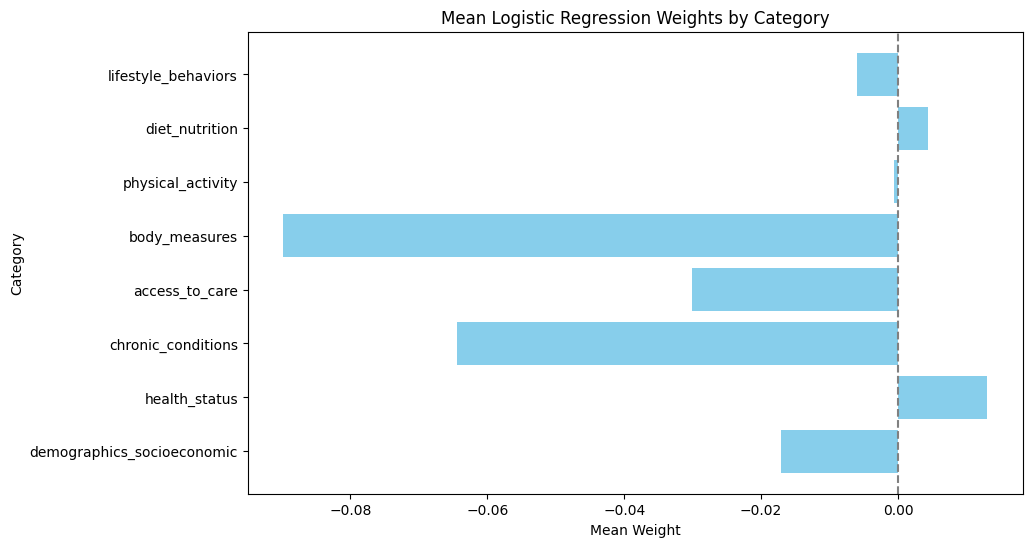

In [8]:
# Plot for each category
plt.figure(figsize=(10,6))
plt.barh(list(category_means.keys()), list(category_means.values()), color='skyblue')
plt.axvline(0, color='gray', linestyle='--')
plt.title("Mean Logistic Regression Weights by Category")
plt.xlabel("Mean Weight")
plt.ylabel("Category")
plt.show()

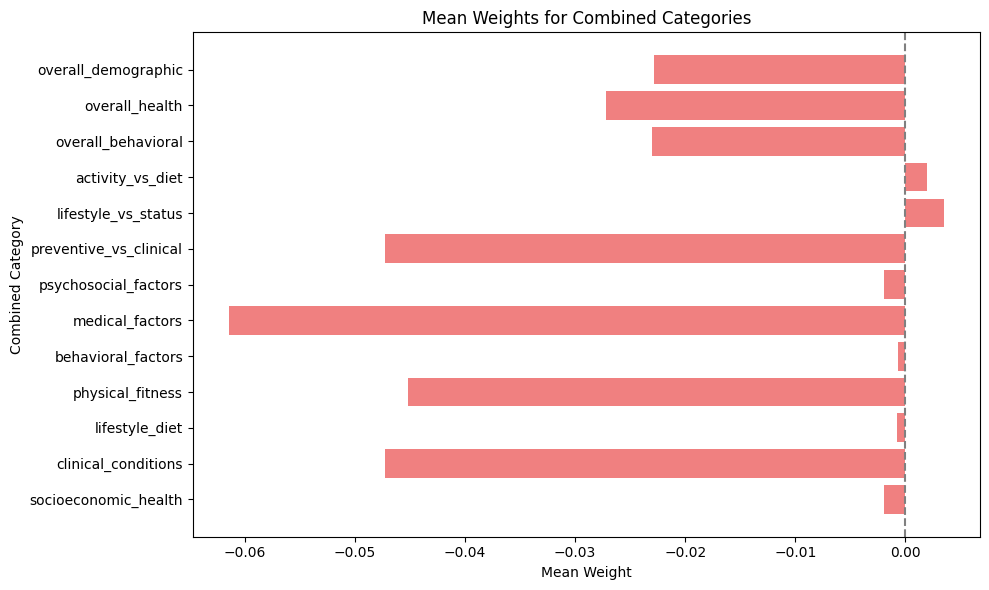

In [9]:
# Plot combined results
plt.figure(figsize=(10,6))
plt.barh(list(combo_means.keys()), list(combo_means.values()), color='lightcoral')
plt.axvline(0, color='gray', linestyle='--')
plt.title("Mean Weights for Combined Categories")
plt.xlabel("Mean Weight")
plt.ylabel("Combined Category")
plt.tight_layout()
plt.show()

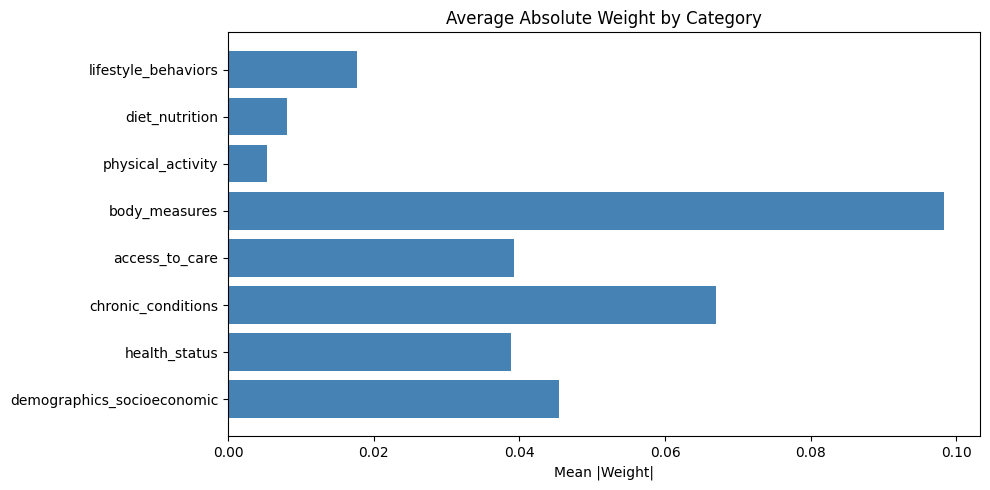

In [10]:
#Plot absolute means

abs_means = {cat: np.mean(np.abs([weights[v] for v in vars_ if v in weights])) for cat, vars_ in categories.items()}

plt.figure(figsize=(10,5))
plt.barh(abs_means.keys(), abs_means.values(), color='steelblue')
plt.title("Average Absolute Weight by Category")
plt.xlabel("Mean |Weight|")
plt.tight_layout()
plt.show()

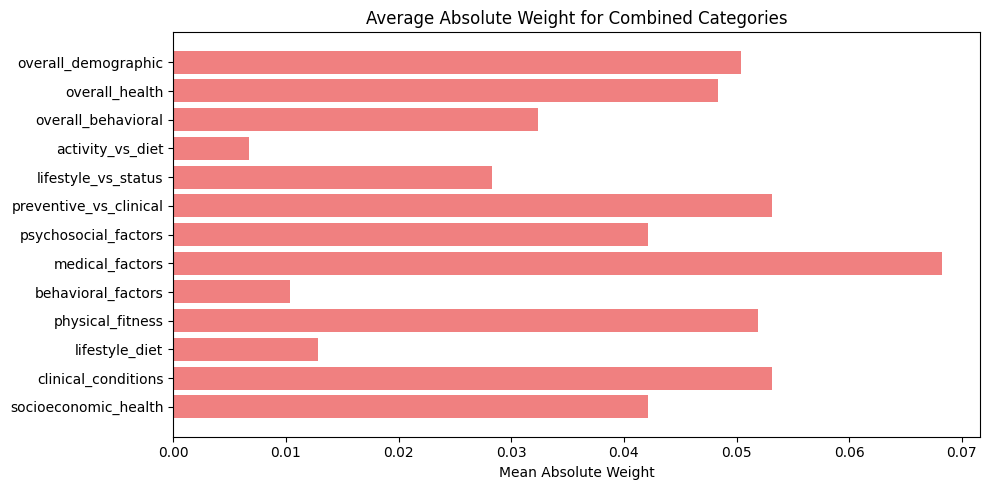

In [11]:
# Plot combined absolute means

abs_combo_means = {cat : np.mean([abs_means[c] for c in cats if c in abs_means]) for cat, cats in combined.items()}

plt.figure(figsize=(10,5))
plt.barh(list(abs_combo_means.keys()), list(abs_combo_means.values()), color='lightcoral')
plt.title("Average Absolute Weight for Combined Categories")
plt.xlabel("Mean Absolute Weight")
plt.tight_layout()
plt.show()

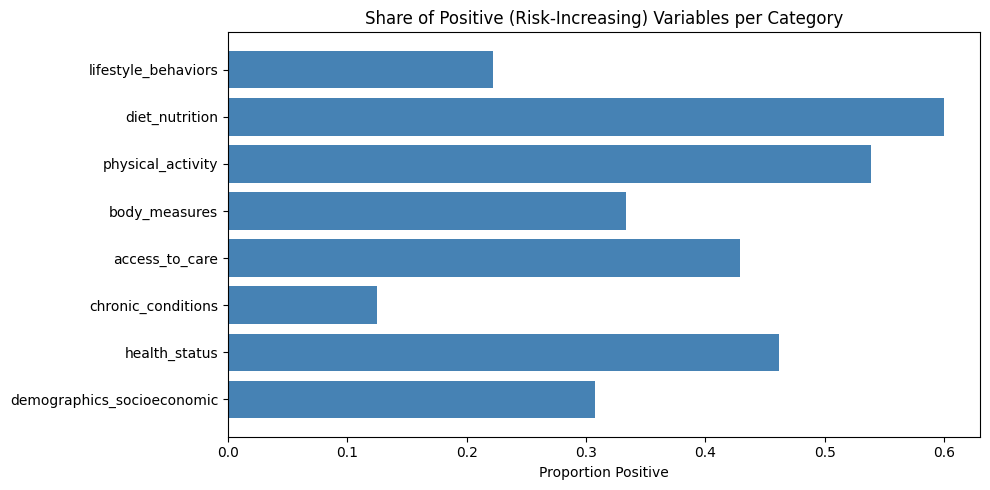

In [12]:
# Compute balance of positive vs negative weights per category

balance = {}
for cat, vars_ in categories.items():
    vals = [weights[v] for v in vars_ if v in weights]
    pos = sum(np.array(vals) > 0)
    neg = sum(np.array(vals) < 0)
    balance[cat] = (pos, neg)

# Plot ratio
ratios = {cat: pos/(pos+neg) if (pos+neg)>0 else np.nan for cat, (pos,neg) in balance.items()}
plt.figure(figsize=(10,5))
plt.barh(ratios.keys(), ratios.values(), color='steelblue')
plt.title("Share of Positive (Risk-Increasing) Variables per Category")
plt.xlabel("Proportion Positive")
plt.tight_layout()
plt.show()

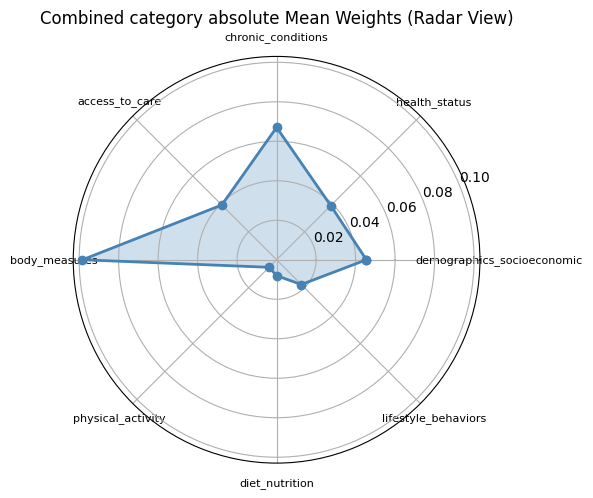

In [13]:
# Radar chart for absolute means
labels = list(abs_means.keys())
values = list(abs_means.values())
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
values += values[:1]
angles += angles[:1]

plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)
ax.plot(angles, values, 'o-', linewidth=2, color='steelblue')
ax.fill(angles, values, alpha=0.25, color='steelblue')
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=8)
ax.set_title("Combined category absolute Mean Weights (Radar View)")
plt.tight_layout()
plt.show()

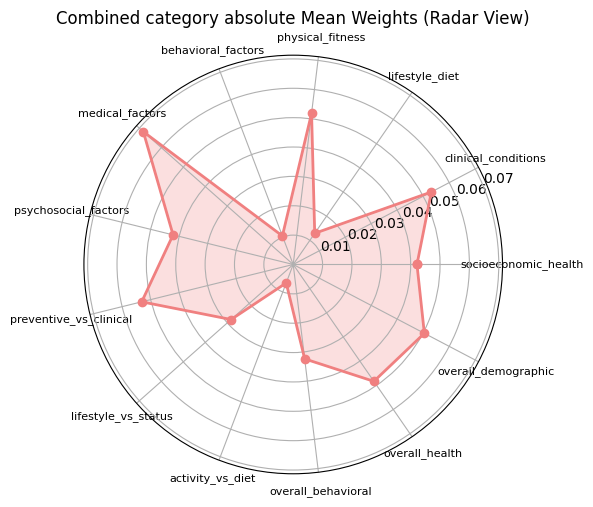

In [14]:
# Radar chart for absolute combined means
labels = list(abs_combo_means.keys())
values = list(abs_combo_means.values())
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
values += values[:1]
angles += angles[:1]

plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)
ax.plot(angles, values, 'o-', linewidth=2, color = 'lightcoral')
ax.fill(angles, values, alpha=0.25, color='lightcoral')
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=8)
ax.set_title("Combined category absolute Mean Weights (Radar View)")
plt.tight_layout()
plt.show()
